## This is a sample Python script that demonstrates basic functionality of Lightkurve

In [1]:
## Load python packages
%matplotlib inline
import numpy as np
import lightkurve as lk
import matplotlib.pyplot as plt

In [2]:
## Load light curve search results of an example target
search_result = lk.search_lightcurve('KIC 6922244', author='Kepler')
search_result

#,mission,year,author,exptime,target_name,distance
,,,,s,,arcsec
0,Kepler Quarter 02,2009,Kepler,60,kplr006922244,0.0
1,Kepler Quarter 02,2009,Kepler,60,kplr006922244,0.0
2,Kepler Quarter 02,2009,Kepler,60,kplr006922244,0.0
3,Kepler Quarter 03,2009,Kepler,60,kplr006922244,0.0
4,Kepler Quarter 03,2009,Kepler,60,kplr006922244,0.0
5,Kepler Quarter 03,2009,Kepler,60,kplr006922244,0.0
6,Kepler Quarter 00,2009,Kepler,1800,kplr006922244,0.0
7,Kepler Quarter 01,2009,Kepler,1800,kplr006922244,0.0
8,Kepler Quarter 02,2009,Kepler,1800,kplr006922244,0.0


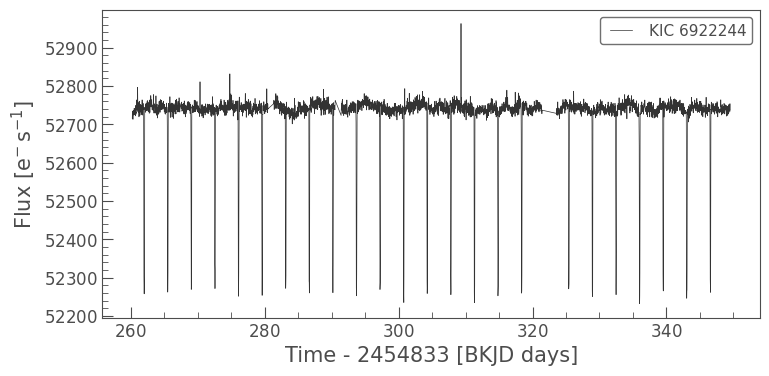

In [3]:
# Let's just look at the long exposures for one quarter
lc = search_result[9].download()
lc.plot() # native plot function in lightkurve
plt.show()

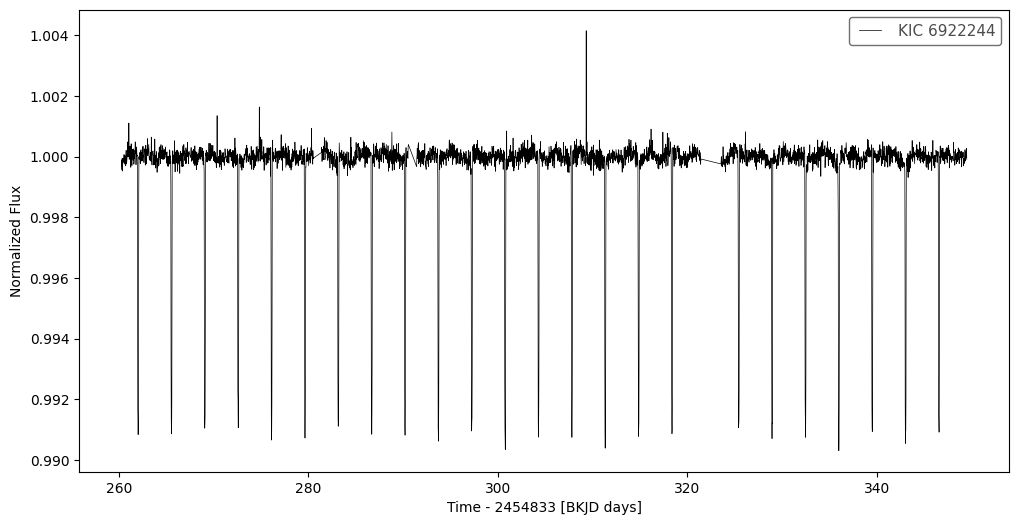

In [4]:
# Clean it up a little and normalize the baseline to 1
fig, ax = plt.subplots(figsize=(12,6))
lc = lc.remove_nans().flatten(window_length=401)
lc.normalize().plot(ax=ax, color='k')
plt.show()

Most prominent frequency: 0.2846 1 / d
Corresponding period: 3.5138 d


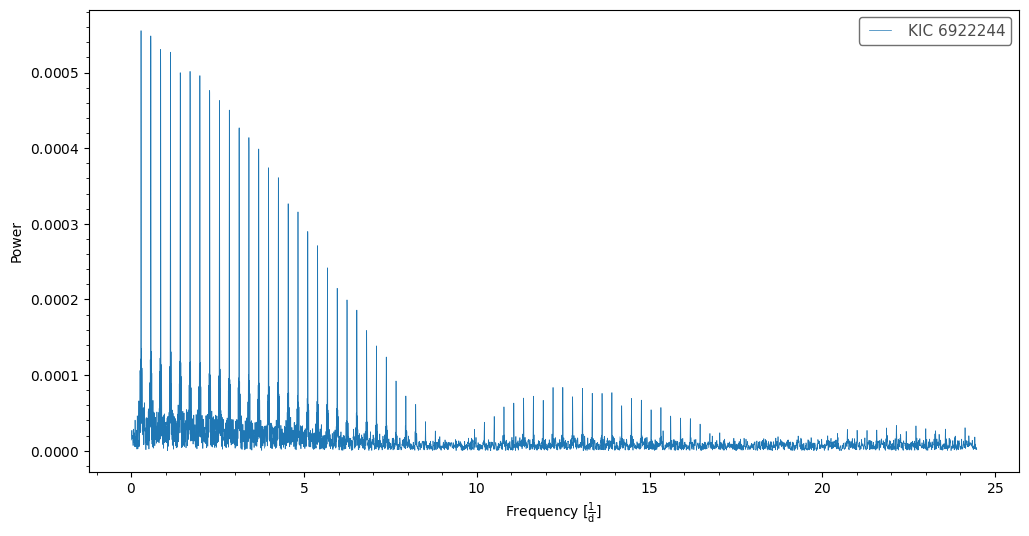

In [5]:
# Use a periodogram to determine the transit period/frequency
pg = lc.to_periodogram(method="lombscargle", oversample_factor=5)
best_frequency = pg.frequency_at_max_power
best_period = pg.period_at_max_power
print(f"Most prominent frequency: {best_frequency.value:.4f} {best_frequency.unit}")
print(f"Corresponding period: {best_period.value:.4f} {best_period.unit}")

fig, ax = plt.subplots(figsize=(12,6))
lc.to_periodogram().plot(ax=ax)
plt.show()

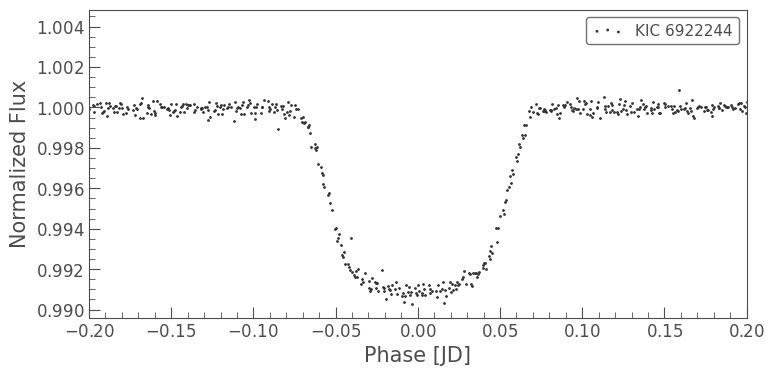

In [6]:
# Fold the lightcurve on the period to get a transit profile
lc_folded = lc.fold(period = 3.5225, epoch_time = 262.02)
lc_folded.scatter()
plt.xlim(-0.2,0.2)
plt.show()